# SOE figures

In [1]:
import matplotlib.pyplot as plt
import cartopy
import numpy as np
import geopandas as gpd
import xarray as xr
import rioxarray
import pandas as pd
import matplotlib.colors as mcolors
import calendar
from scipy.stats import linregress
import os


In [4]:
version = 1.1 #or 2.0
#version 1.1 uses chl and 2.0 uses OWT as biological input
#Open water mass data (monthly)
if os.path.isfile(fr'C:\Users\haley.synan\Documents\DATA\CLIMATOLOGIES\NEScapes_V{version}_all.nc'):
    print("File exists... opening")
    ds = xr.open_dataset(fr'C:\Users\haley.synan\Documents\DATA\CLIMATOLOGIES\NEScapes_V{version}_all.nc')
else: 
    print("File doesn't exist... creating")
    ds = xr.open_mfdataset(fr"X:\NESCAPES\V{version}\*.nc",
        chunks={"time": -1, "latitude": 200, "longitude": 200}, 
        compat="override",
        data_vars="minimal",
        coords="minimal",
        parallel=True
    )
    ds.to_netcdf(fr'C:\Users\haley.synan\Documents\DATA\CLIMATOLOGIES\NEScapes_V{version}_all.nc')

#Open region shapefiles
gdf = gpd.read_file(r'C:\Users\haley.synan\Documents\DATA\SHAPEFILES\NES_5REG\NES_5REGIONS.shp')
gdf = gdf.set_crs("EPSG:4326")
gdf = gdf.to_crs("EPSG:3857")

File exists... opening


In [13]:
poly_name = ['MAB','GB','GOM']
poly_list = [[0,1],[2],[3,4]]

n_masses = np.unique(ds.water_mass[0])[~np.isnan(np.unique(ds.water_mass[0]))]
if len(n_masses) == 8:
    dis_hex = ['#000080','#0072B2','#56B4E9','#009E73','#F0E442','#E69F00','#D55E00','#CC79A7']
    cm = mcolors.LinearSegmentedColormap.from_list("okabe_ito", dis_hex, N=len(dis_hex))
elif len(n_masses) == 9:
    dis_hex = ['#000080','#0072B2','#56B4E9','#009E73','#F0E442','#E69F00','#D55E00','#CC79A7','#BBBBBB']
    cm = mcolors.LinearSegmentedColormap.from_list("okabe_ito", dis_hex, N=len(dis_hex))

if version == 1.1:
    water_mass_colors = {
    'Sargasso Sea': dis_hex[0],
    'Gulf Stream': dis_hex[1],
    'Slope': dis_hex[2],
    'Shelfbreak': dis_hex[3],
    'Scotian Shelf': dis_hex[4],
    'Gulf of Maine': dis_hex[5],
    'Mid-Atlantic Shelf': dis_hex[6],
    'Georges Bank': dis_hex[7]
    }
    water_mass_names = ['Sargasso Sea','Gulf Stream','Slope','Shelfbreak','Scotian Shelf','Gulf of Maine','Mid-Atlantic Shelf','Georges Bank']
    wmass_labels = ['Sargasso Sea','Gulf Stream','Slope','Shelfbreak','Scotian Shelf','Gulf of Maine','Mid-Atlantic Shelf','Georges Bank']
elif version == 2.0: 
    water_mass_colors = {
    'Georges Bank+': dis_hex[0],  # Dark Blue
    'Scotian Shelf': dis_hex[1],  # Medium Blue
    'Gulf of Maine': dis_hex[2],  # Light Blue
    'Mid-Atlantic Shelf': dis_hex[3],  # Dark Green (e.g., for algae/vegetation)
    'Shelfbreak transition': dis_hex[4],  # Medium Blue
    'Offshore Shelf': dis_hex[5],  # Light Blue
    'Slope Sea': dis_hex[6],  # Dark Green
    'Gulf Stream':dis_hex[7],
    'Sargasso Sea':dis_hex[8]
    }
    water_mass_names = ['Georges Bank+','Scotian Shelf','Gulf of Maine','Mid-Atlantic Shelf','Shelfbreak transition','Offshore Shelf','Slope Sea','Gulf Stream','Sargasso Sea']
    wmass_labels=['Georges Bank+','Scotian Shelf','Gulf of Maine','Mid-Atlantic Shelf','Shelfbreak transition','Offshore Shelf','Slope Sea','Gulf Stream','Sargasso Sea']
dfs_perc = []
for x in range(3): 
    print(f'Starting processing of {poly_name[x]}')
    # clip data to region shapes
    first_polygon = gdf.iloc[poly_list[x]] 
    if ds.rio.crs is None:
        ds.rio.write_crs("EPSG:4326", inplace=True)
    first_polygon = first_polygon.to_crs(ds.rio.crs)
    clipped_ds = ds.rio.clip(
        first_polygon.geometry,
        first_polygon.crs,
        all_touched=True,
        drop=True
    )

    da = clipped_ds['water_mass']
    spatial_dims = [dim for dim in da.dims if dim != 'time']
    unique_vals = np.unique(da.values[~np.isnan(da.values)])
    categories = [int(val) for val in unique_vals]
    print('Clipped to shapefile')
    #count total valid pixels
    total_valid_pixels = da.notnull().sum(dim=spatial_dims)
    
    # calculate percentages
    timeseries_dict = {}
    for cat in categories:
        # Count how many pixels in each water mass
        cat_count = (da == cat).sum(dim=spatial_dims)
        
        # turn into percentages
        cat_percent = (cat_count / total_valid_pixels) * 100
        
        # create dataframe
        timeseries_dict[water_mass_names[cat]] = cat_percent.to_pandas()
    
    # 5. Combine everything into a pandas DataFrame
    df_percentages = pd.DataFrame(timeseries_dict)
    df_percentages.insert(0, 'subarea', [poly_name[x]]*len(df_percentages))
    df_percentages.insert(0, 'period_description', ['Monthly']*len(df_percentages))
    dfs_perc.append(df_percentages)
    print(f'Done with {poly_name[x]}')
df_spat = pd.concat(dfs_perc) 
df_spat.to_csv(r'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\DATA\spatial_coverage_extracted.jpg')

Starting processing of MAB
Clipped to shapefile
Done with MAB
Starting processing of GB
Clipped to shapefile
Done with GB
Starting processing of GOM
Clipped to shapefile
Done with GOM


# Spatial plots


## Time series of % coverage (Regional)

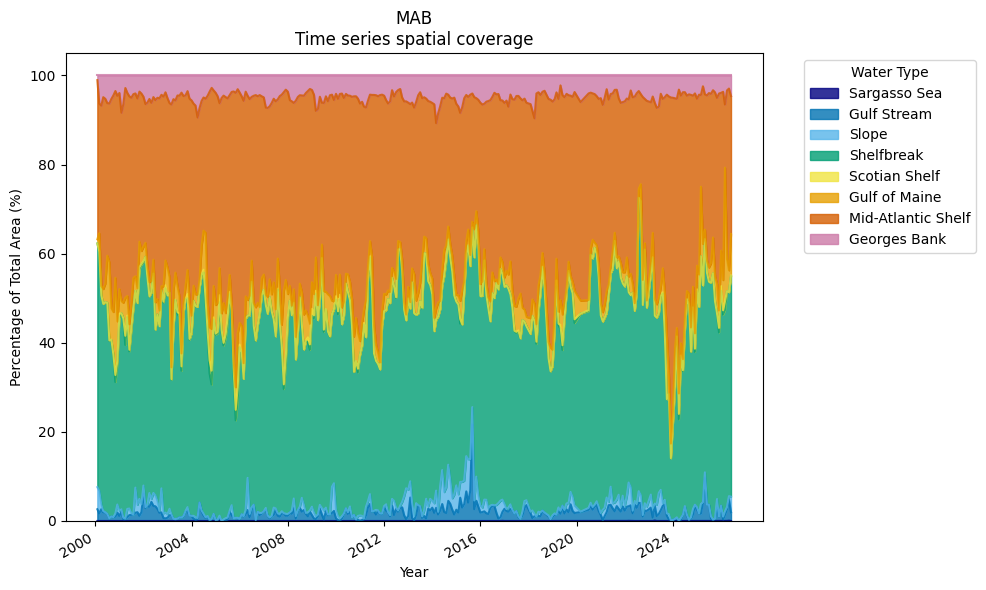

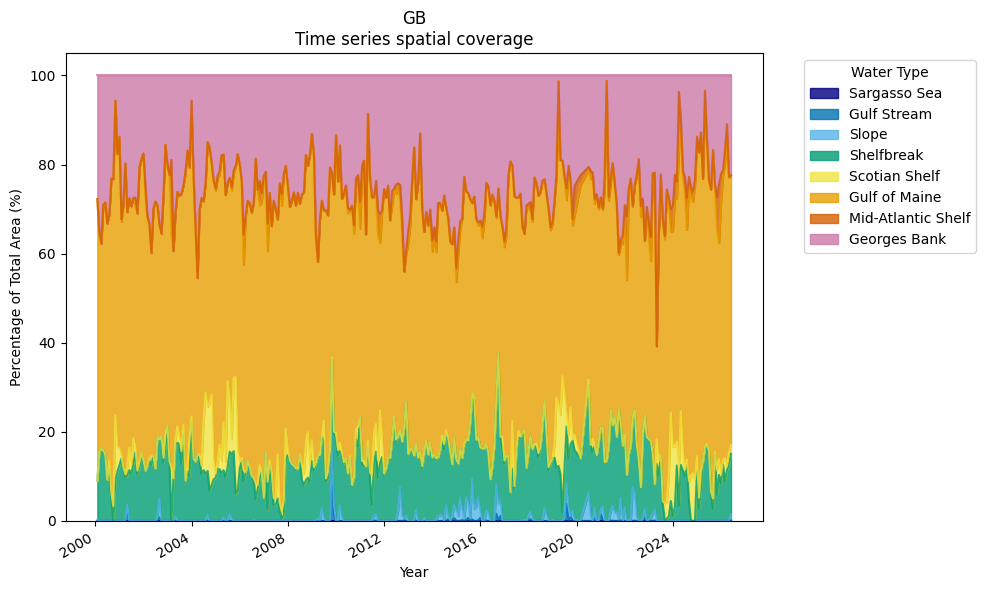

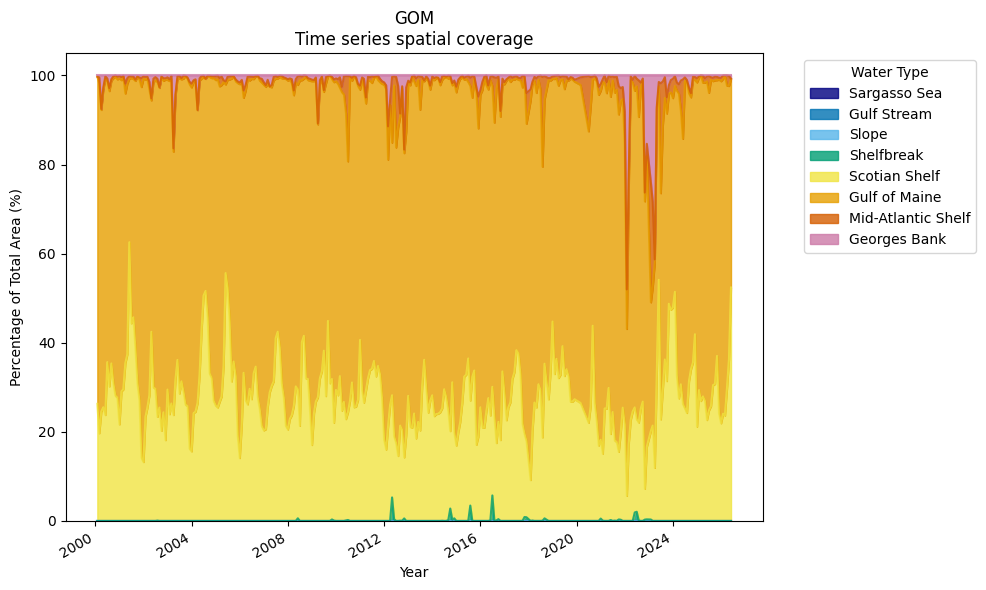

In [6]:
master_order = list(water_mass_colors.keys())

for x in range(3):
    df_percentages = df_spat[df_spat.subarea==poly_name[x]]
    for water_type in master_order:
        if water_type not in df_percentages.columns:
            df_percentages[water_type] = 0.0
            
    # Force the dataframe columns into the exact order of the dictionary
    df_percentages = df_percentages[master_order]

    # Plot the standardized dataframe
    ax = df_percentages.plot.area(
        figsize=(10, 6), 
        color=water_mass_colors, 
        alpha=0.8
    )
    
    plt.title(f"{poly_name[x]}\nTime series spatial coverage")
    plt.ylabel("Percentage of Total Area (%)")
    plt.xlabel("Year")
    
    # Move the legend outside the plot
    plt.legend(title="Water Type", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\{poly_name[x]}_timeseries_spatial_coverage.jpg')
    plt.show()

## Current year with climatological spatial coverage (Regional)

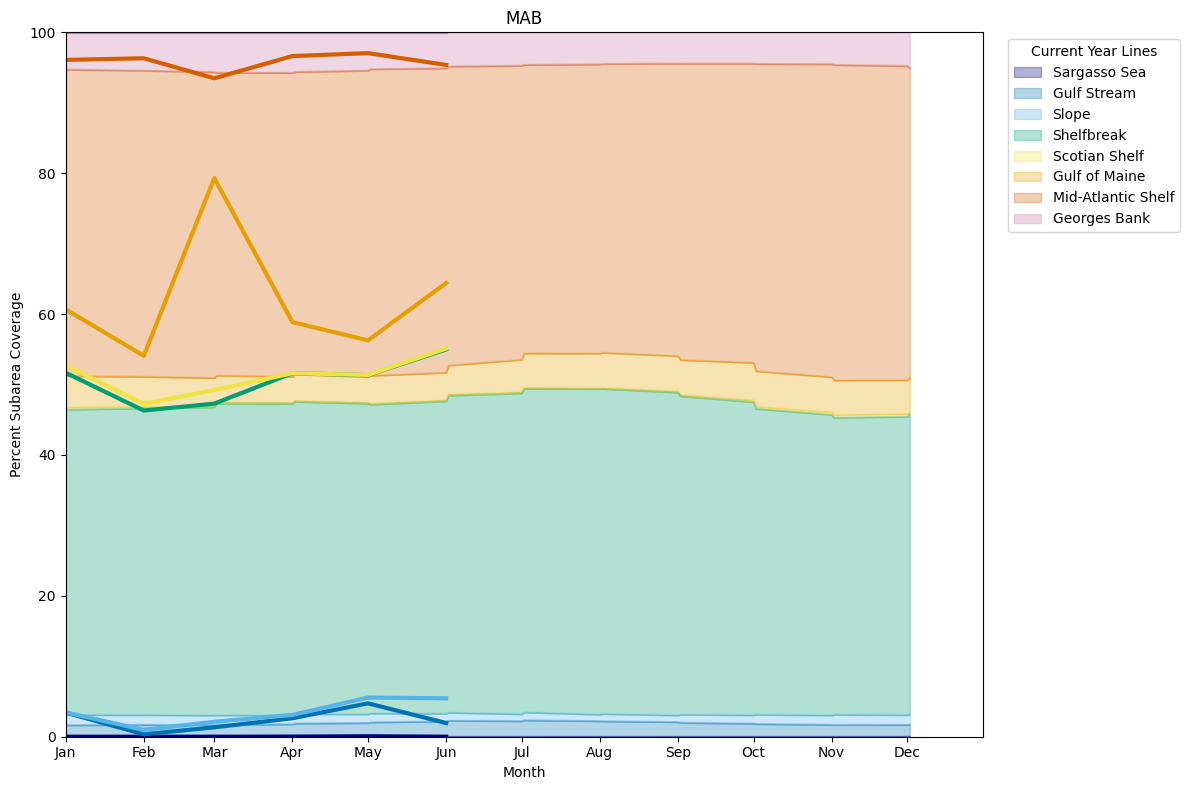

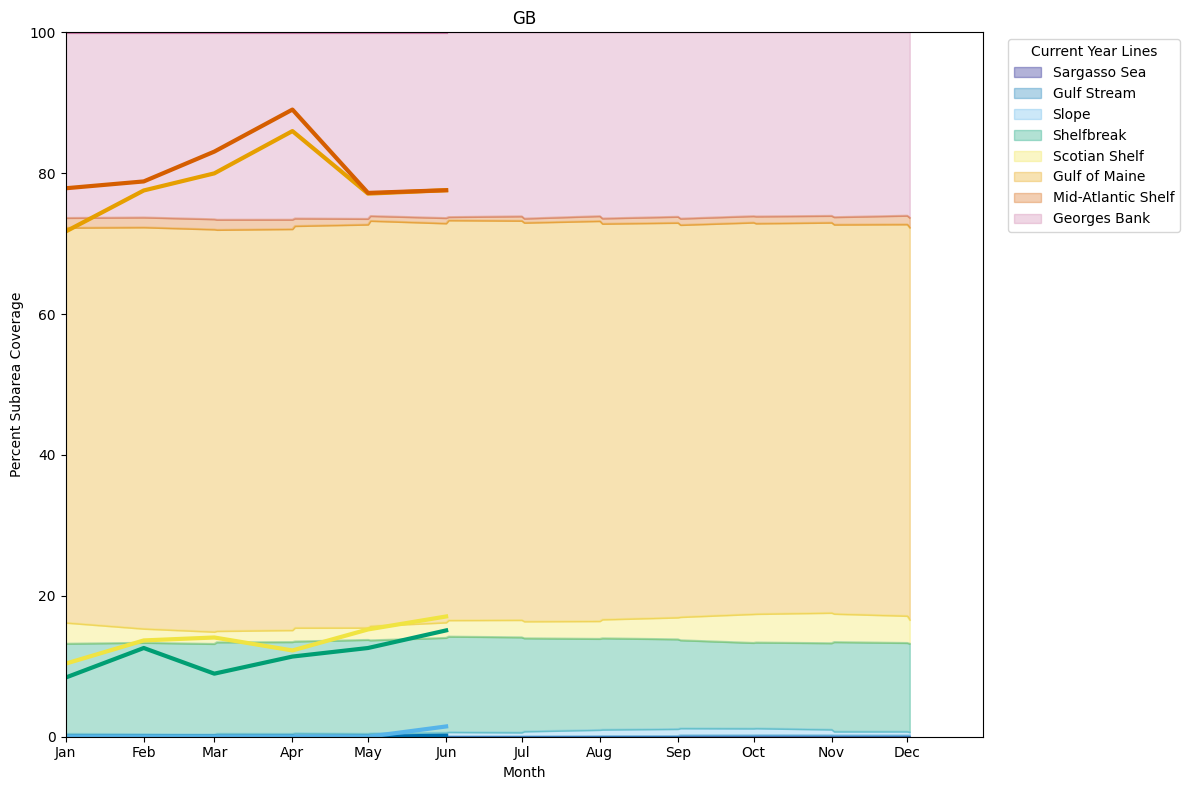

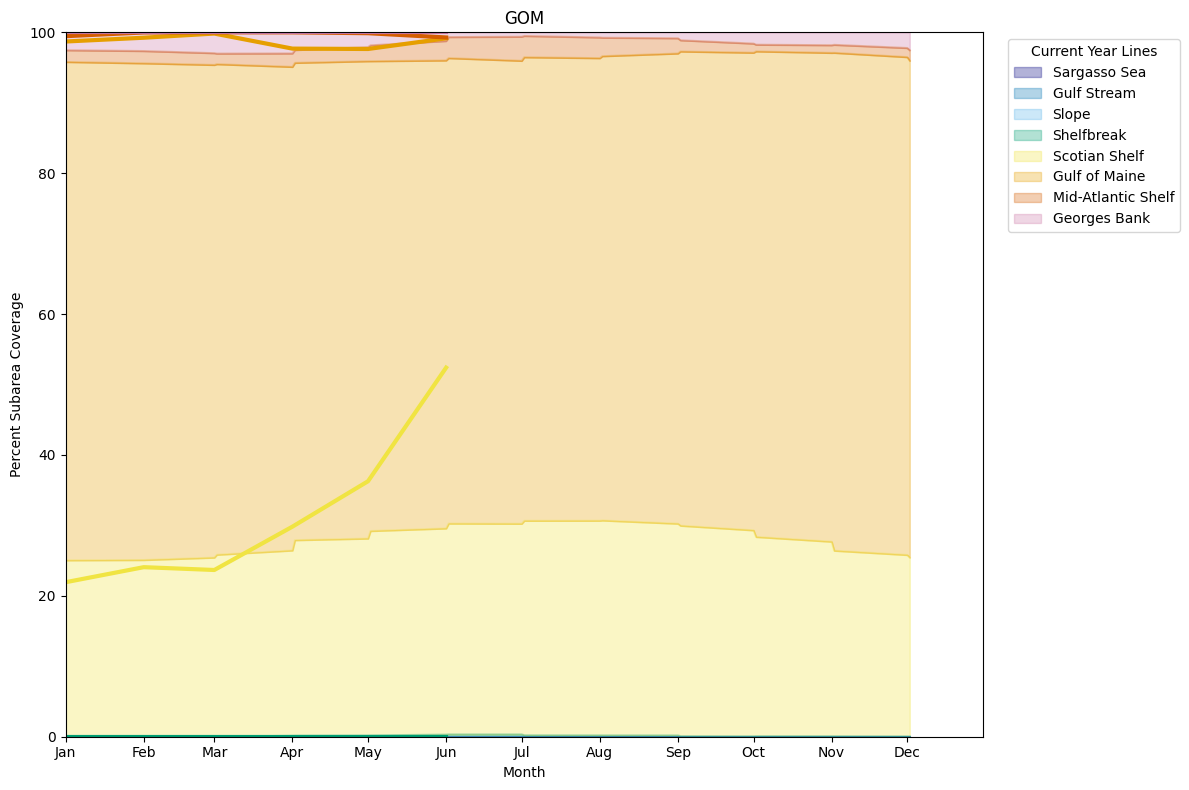

In [7]:
# plot 1 
for x in range(3):
    df_percentages = df_spat[df_spat.subarea==poly_name[x]]
    # 1. Split data into historical and current
    last_year = df_percentages.index.year.max()
    df_historical = df_percentages[df_percentages.index.year < last_year].drop(['period_description','subarea'],axis=1)
    df_current = df_percentages[df_percentages.index.year == last_year].drop(['period_description','subarea'],axis=1)
    
    # 2. Calculate the historical average and current year (both sum to 100%)
    #df_clim_mean = df_historical.groupby(df_historical.index.dayofyear).mean()
    df_daily = df_historical.groupby(df_historical.index.dayofyear).mean()
    window = 7
    pad = window // 2
    df_padded = pd.concat([df_daily.iloc[-pad:], df_daily, df_daily.iloc[:pad]])
    df_smoothed = df_padded.rolling(window=window, center=True, min_periods=1).mean()
    df_clim_mean = df_smoothed.iloc[pad:-pad]
    
    df_current_grouped = df_current.groupby(df_current.index.dayofyear).mean()
    
    # 3. Create the plot
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Ensure color list matches the DataFrame columns
    color_list = [water_mass_colors.get(col, '#333333') for col in df_clim_mean.columns]
    
    # --- BACKGROUND: Historical Average as a Stacked Area ---
    df_clim_mean.plot.area(
        ax=ax, 
        color=color_list, 
        alpha=0.3,       # Make it semi-transparent so the lines stand out
        legend=False     # We'll build a custom legend
    )
    
    # --- FOREGROUND: Current Year as Stacked Lines ---
    # We must calculate the cumulative sum across columns so the lines 
    # match the boundaries of the stacked area chart beneath them.
    current_cumulative = df_current_grouped.cumsum(axis=1)
    
    # Plot each boundary line
    for col in current_cumulative.columns:
        ax.plot(
            current_cumulative.index, 
            current_cumulative[col], 
            color=water_mass_colors[col], 
            linewidth=3,
            #label=f"{col} (Year {last_year})"
        )
    

    month_starts = [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335]
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                   'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    ax.set_xticks(month_starts)
    ax.set_xticklabels(month_names)
    

    plt.title(f"{poly_name[x]}")
    plt.ylabel("Percent Subarea Coverage")
    plt.xlabel("Month")
    plt.xlim(1, 365)
    plt.ylim(0, 100) # Lock the Y-axis to exactly 100%
    
    ax.legend(title="Current Year Lines", bbox_to_anchor=(1.02, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\{poly_name[x]}_{last_year}_spatial_coverage.jpg')
    plt.show()

## Time series of 1 water mass coverage (Regional)

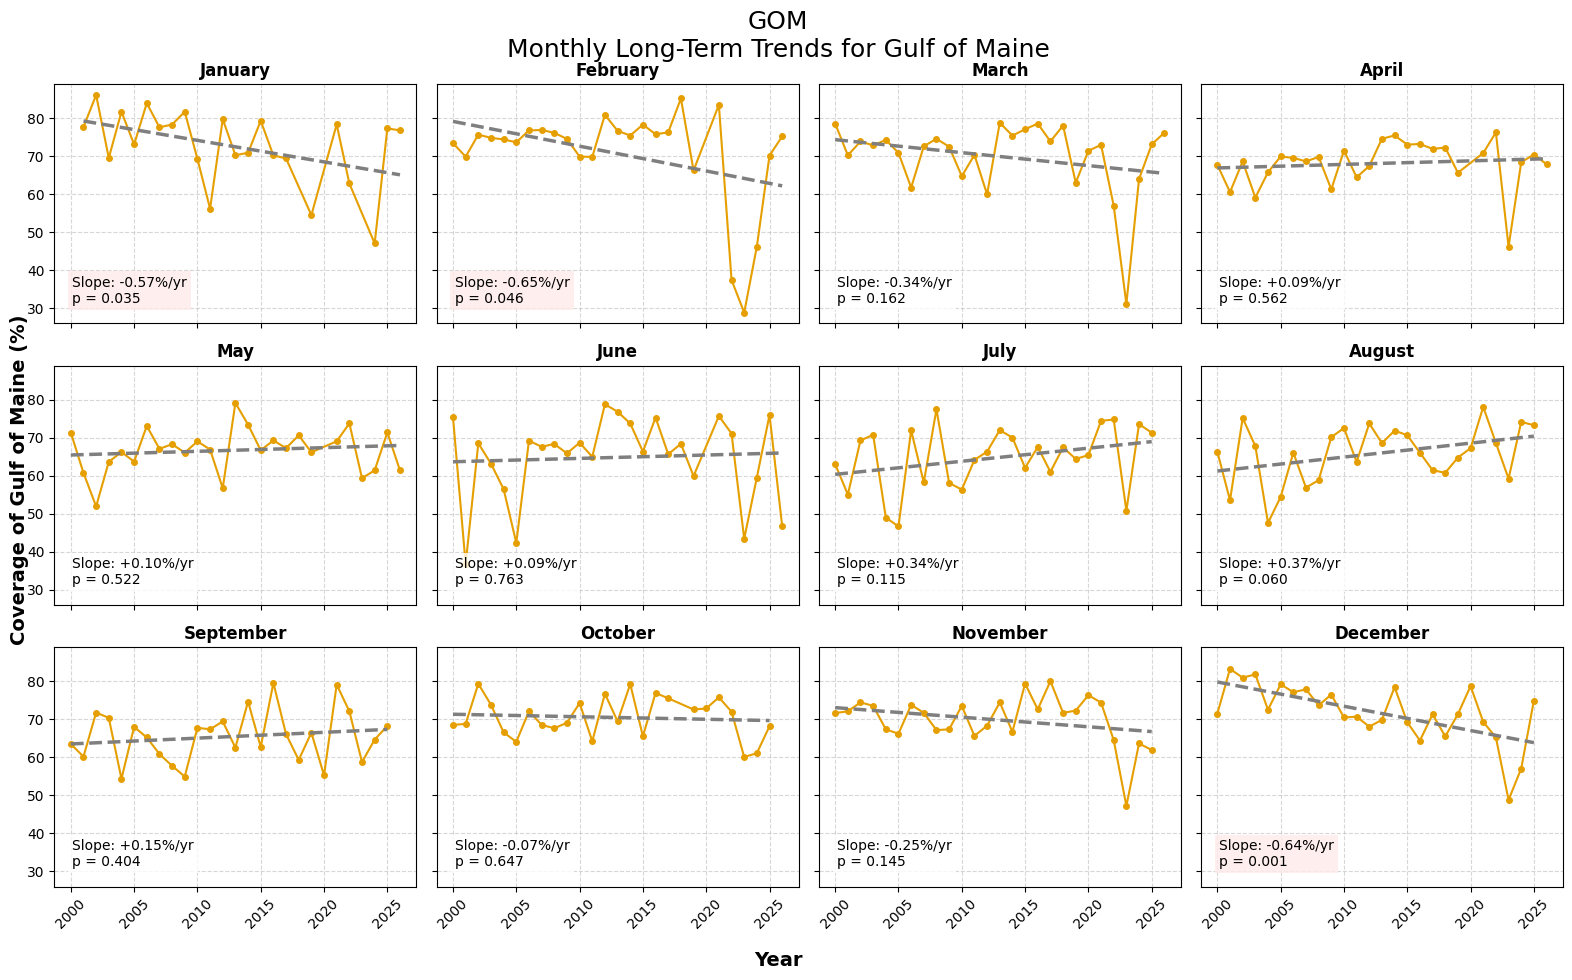

In [8]:
#Define your target water mass
target_type = "Gulf of Maine"
xx=2
target_color = water_mass_colors.get(target_type, "#4292c6") 
df_percentages = dfs_perc[xx]
# Set your significance threshold (0.05 means we require 95% confidence that the slope is not zero)
alpha = 0.05 

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for month_num in range(1, 13):
    ax = axes[month_num - 1] 
    
    month_data = df_percentages[df_percentages.index.month == month_num][target_type]
    yearly_data = month_data.groupby(month_data.index.year).mean().dropna()
    
    if yearly_data.empty:
        ax.set_title(calendar.month_name[month_num])
        continue
        
    x = yearly_data.index.values
    y = yearly_data.values
    
    # Plot actual coverage
    ax.plot(x, y, marker='o', color=target_color, markersize=4, linewidth=1.5)
    
    #Calculate Linear Regression with p-value
    if len(x) > 2: # Need at least 3 points for a valid statistical test
        res = linregress(x, y)
        slope = res.slope
        p_val = res.pvalue
        
        # Calculate the Y values for the trend line
        trend_y = slope * x + res.intercept
        
        is_significant = p_val < alpha
        line_color = '#7f7f7f' # Gray
        line_style = '--'      # Dashed
        weight = 'normal'
            
        ax.plot(x, trend_y, color=line_color, linestyle=line_style, linewidth=2.5)
        
        box_color = '#ffeaea' if is_significant else 'white'
        
        trend_text = f"Slope: {slope:+.2f}%/yr\np = {p_val:.3f}"
        ax.text(0.05, 0.20, trend_text, transform=ax.transAxes, 
                fontsize=10, fontweight=weight, verticalalignment='top',
                bbox=dict(facecolor=box_color, alpha=0.8, edgecolor='none', pad=3))

    ax.set_title(calendar.month_name[month_num], fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=45)

fig.supylabel(f"Coverage of {target_type} (%)", fontsize=14, fontweight='bold')
fig.supxlabel("Year", fontsize=14, fontweight='bold')
fig.suptitle(f"{poly_name[xx]}\nMonthly Long-Term Trends for {target_type}", fontsize=18, y=.97)

plt.tight_layout()
plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\GOM_GOM_timeseries.jpg')
plt.show()

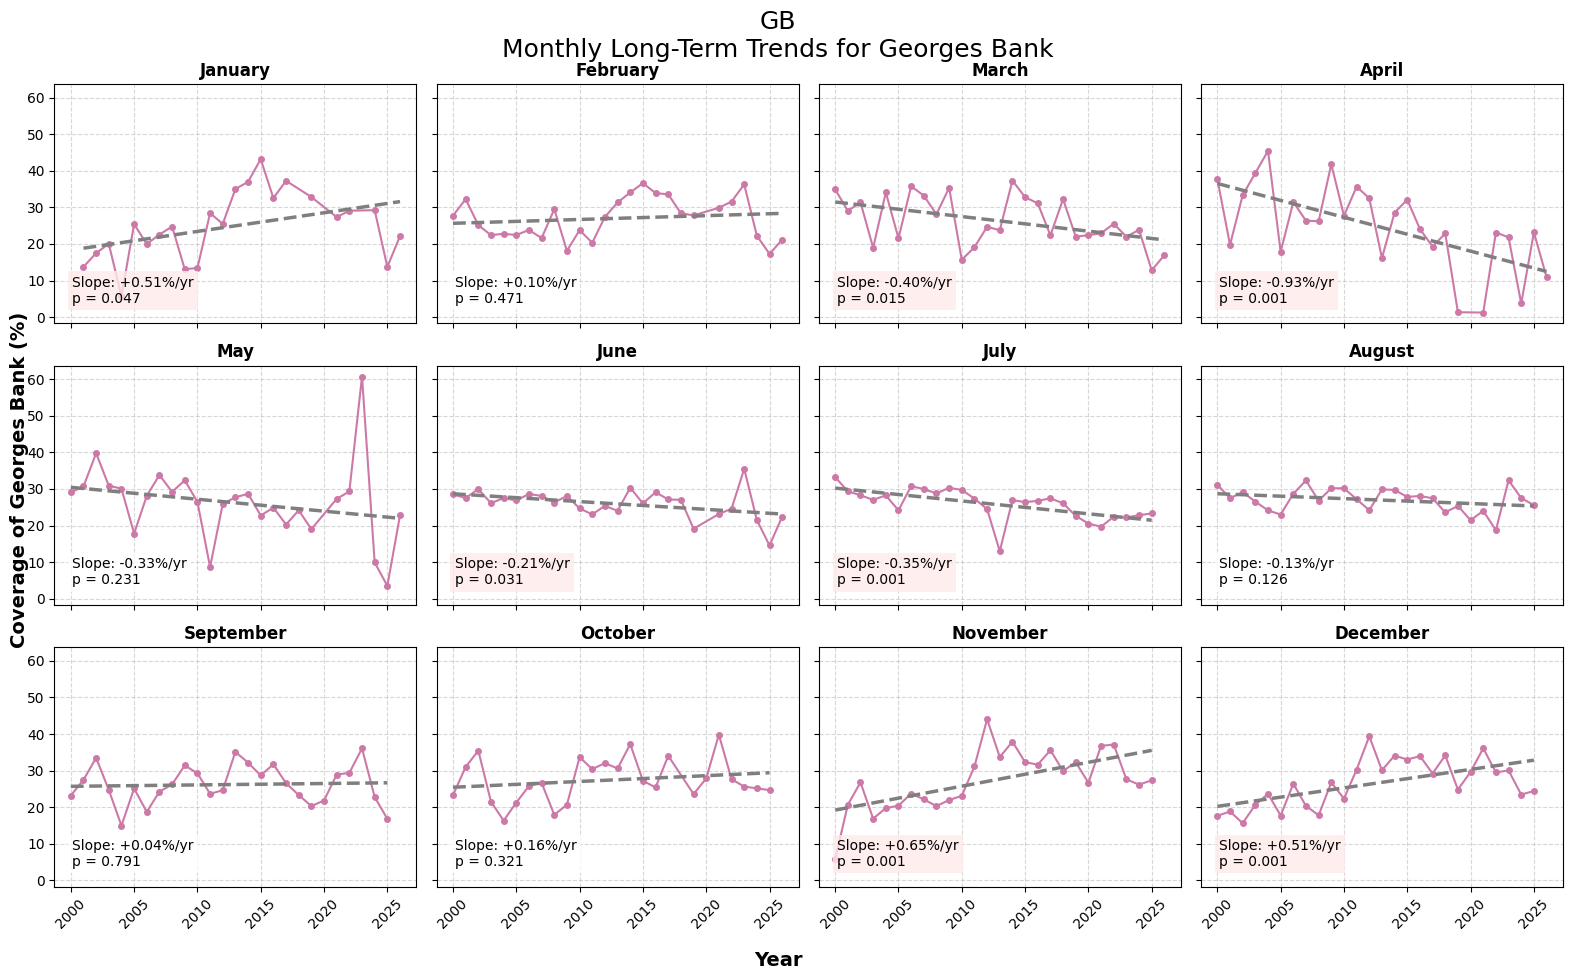

In [9]:
#Define your target water mass
target_type = "Georges Bank"
xx=1
target_color = water_mass_colors.get(target_type, "#4292c6") 
df_percentages = dfs_perc[xx]
# Set your significance threshold (0.05 means we require 95% confidence that the slope is not zero)
alpha = 0.05 

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for month_num in range(1, 13):
    ax = axes[month_num - 1] 
    
    month_data = df_percentages[df_percentages.index.month == month_num][target_type]
    yearly_data = month_data.groupby(month_data.index.year).mean().dropna()
    
    if yearly_data.empty:
        ax.set_title(calendar.month_name[month_num])
        continue
        
    x = yearly_data.index.values
    y = yearly_data.values
    
    # Plot actual coverage
    ax.plot(x, y, marker='o', color=target_color, markersize=4, linewidth=1.5)
    
    #Calculate Linear Regression with p-value
    if len(x) > 2: # Need at least 3 points for a valid statistical test
        res = linregress(x, y)
        slope = res.slope
        p_val = res.pvalue
        
        # Calculate the Y values for the trend line
        trend_y = slope * x + res.intercept
        
        is_significant = p_val < alpha
        line_color = '#7f7f7f' # Gray
        line_style = '--'      # Dashed
        weight = 'normal'
            
        ax.plot(x, trend_y, color=line_color, linestyle=line_style, linewidth=2.5)
        
        box_color = '#ffeaea' if is_significant else 'white'
        
        trend_text = f"Slope: {slope:+.2f}%/yr\np = {p_val:.3f}"
        ax.text(0.05, 0.20, trend_text, transform=ax.transAxes, 
                fontsize=10, fontweight=weight, verticalalignment='top',
                bbox=dict(facecolor=box_color, alpha=0.8, edgecolor='none', pad=3))

    ax.set_title(calendar.month_name[month_num], fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=45)

fig.supylabel(f"Coverage of {target_type} (%)", fontsize=14, fontweight='bold')
fig.supxlabel("Year", fontsize=14, fontweight='bold')
fig.suptitle(f"{poly_name[xx]}\nMonthly Long-Term Trends for {target_type}", fontsize=18, y=.97)

plt.tight_layout()
plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\GB_GB_timeseries.jpg')
plt.show()

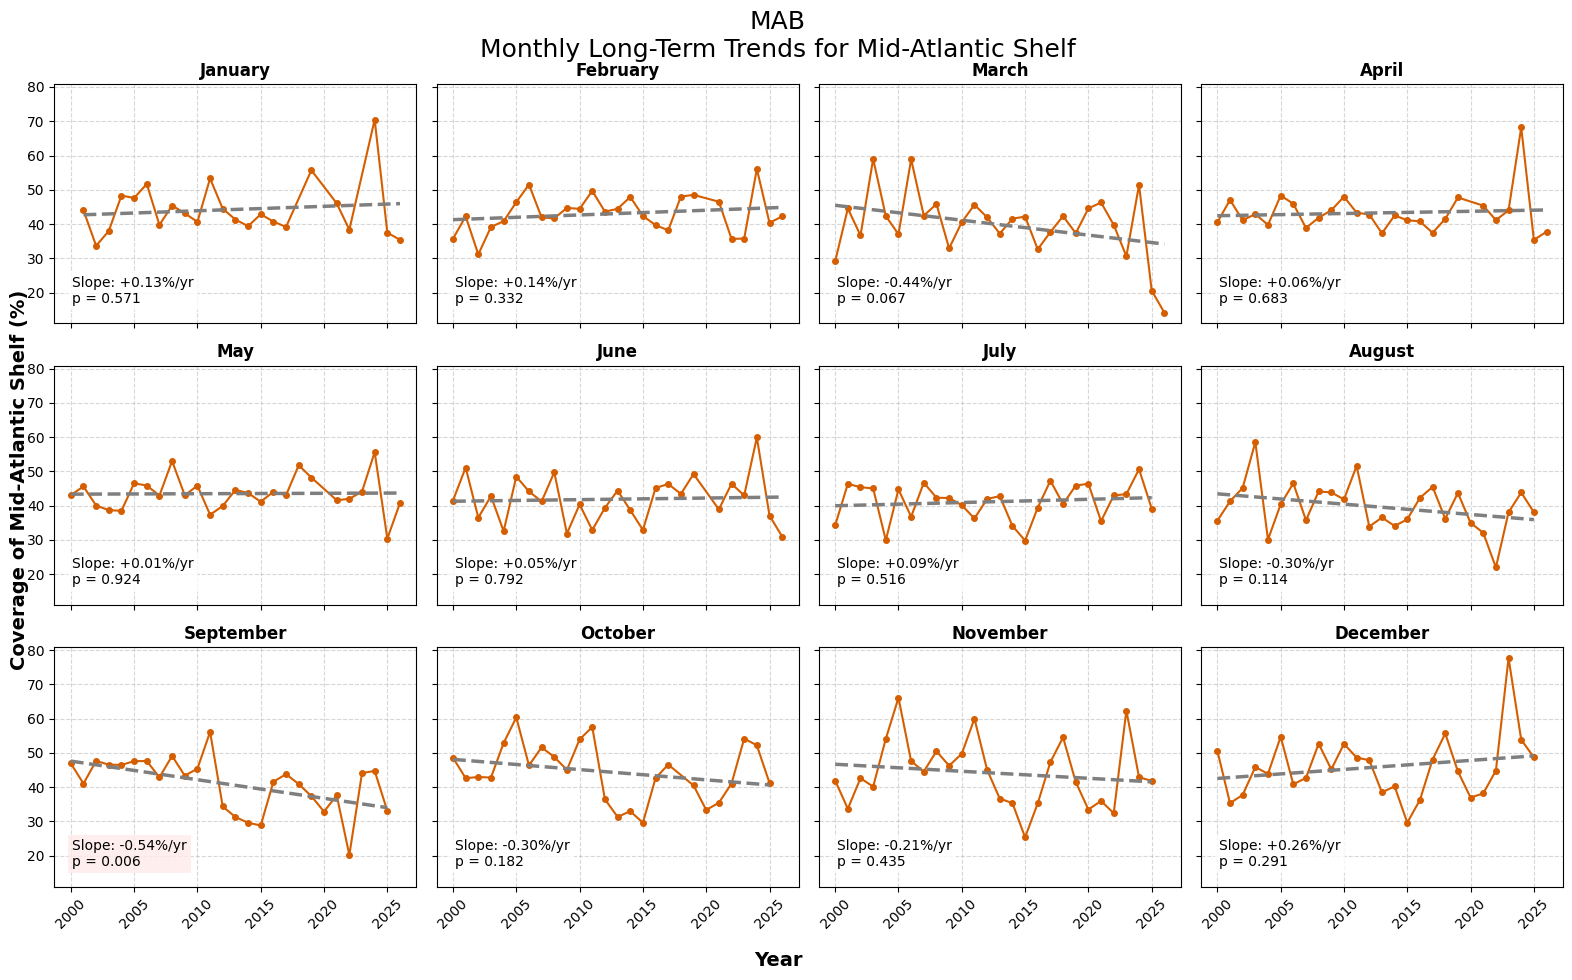

In [10]:
#Define your target water mass
target_type = "Mid-Atlantic Shelf"
xx=0
target_color = water_mass_colors.get(target_type, "#4292c6") 
df_percentages = dfs_perc[xx]
# Set your significance threshold (0.05 means we require 95% confidence that the slope is not zero)
alpha = 0.05 

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for month_num in range(1, 13):
    ax = axes[month_num - 1] 
    
    month_data = df_percentages[df_percentages.index.month == month_num][target_type]
    yearly_data = month_data.groupby(month_data.index.year).mean().dropna()
    
    if yearly_data.empty:
        ax.set_title(calendar.month_name[month_num])
        continue
        
    x = yearly_data.index.values
    y = yearly_data.values
    
    # Plot actual coverage
    ax.plot(x, y, marker='o', color=target_color, markersize=4, linewidth=1.5)
    
    #Calculate Linear Regression with p-value
    if len(x) > 2: # Need at least 3 points for a valid statistical test
        res = linregress(x, y)
        slope = res.slope
        p_val = res.pvalue
        
        # Calculate the Y values for the trend line
        trend_y = slope * x + res.intercept
        
        is_significant = p_val < alpha
        line_color = '#7f7f7f' # Gray
        line_style = '--'      # Dashed
        weight = 'normal'
            
        ax.plot(x, trend_y, color=line_color, linestyle=line_style, linewidth=2.5)
        
        box_color = '#ffeaea' if is_significant else 'white'
        
        trend_text = f"Slope: {slope:+.2f}%/yr\np = {p_val:.3f}"
        ax.text(0.05, 0.20, trend_text, transform=ax.transAxes, 
                fontsize=10, fontweight=weight, verticalalignment='top',
                bbox=dict(facecolor=box_color, alpha=0.8, edgecolor='none', pad=3))

    ax.set_title(calendar.month_name[month_num], fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='x', rotation=45)

fig.supylabel(f"Coverage of {target_type} (%)", fontsize=14, fontweight='bold')
fig.supxlabel("Year", fontsize=14, fontweight='bold')
fig.suptitle(f"{poly_name[xx]}\nMonthly Long-Term Trends for {target_type}", fontsize=18, y=.97)

plt.tight_layout()
plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\MAB_MAS_timeseries.jpg')
plt.show()

## Anomaly time series

Getting Slope for MAB


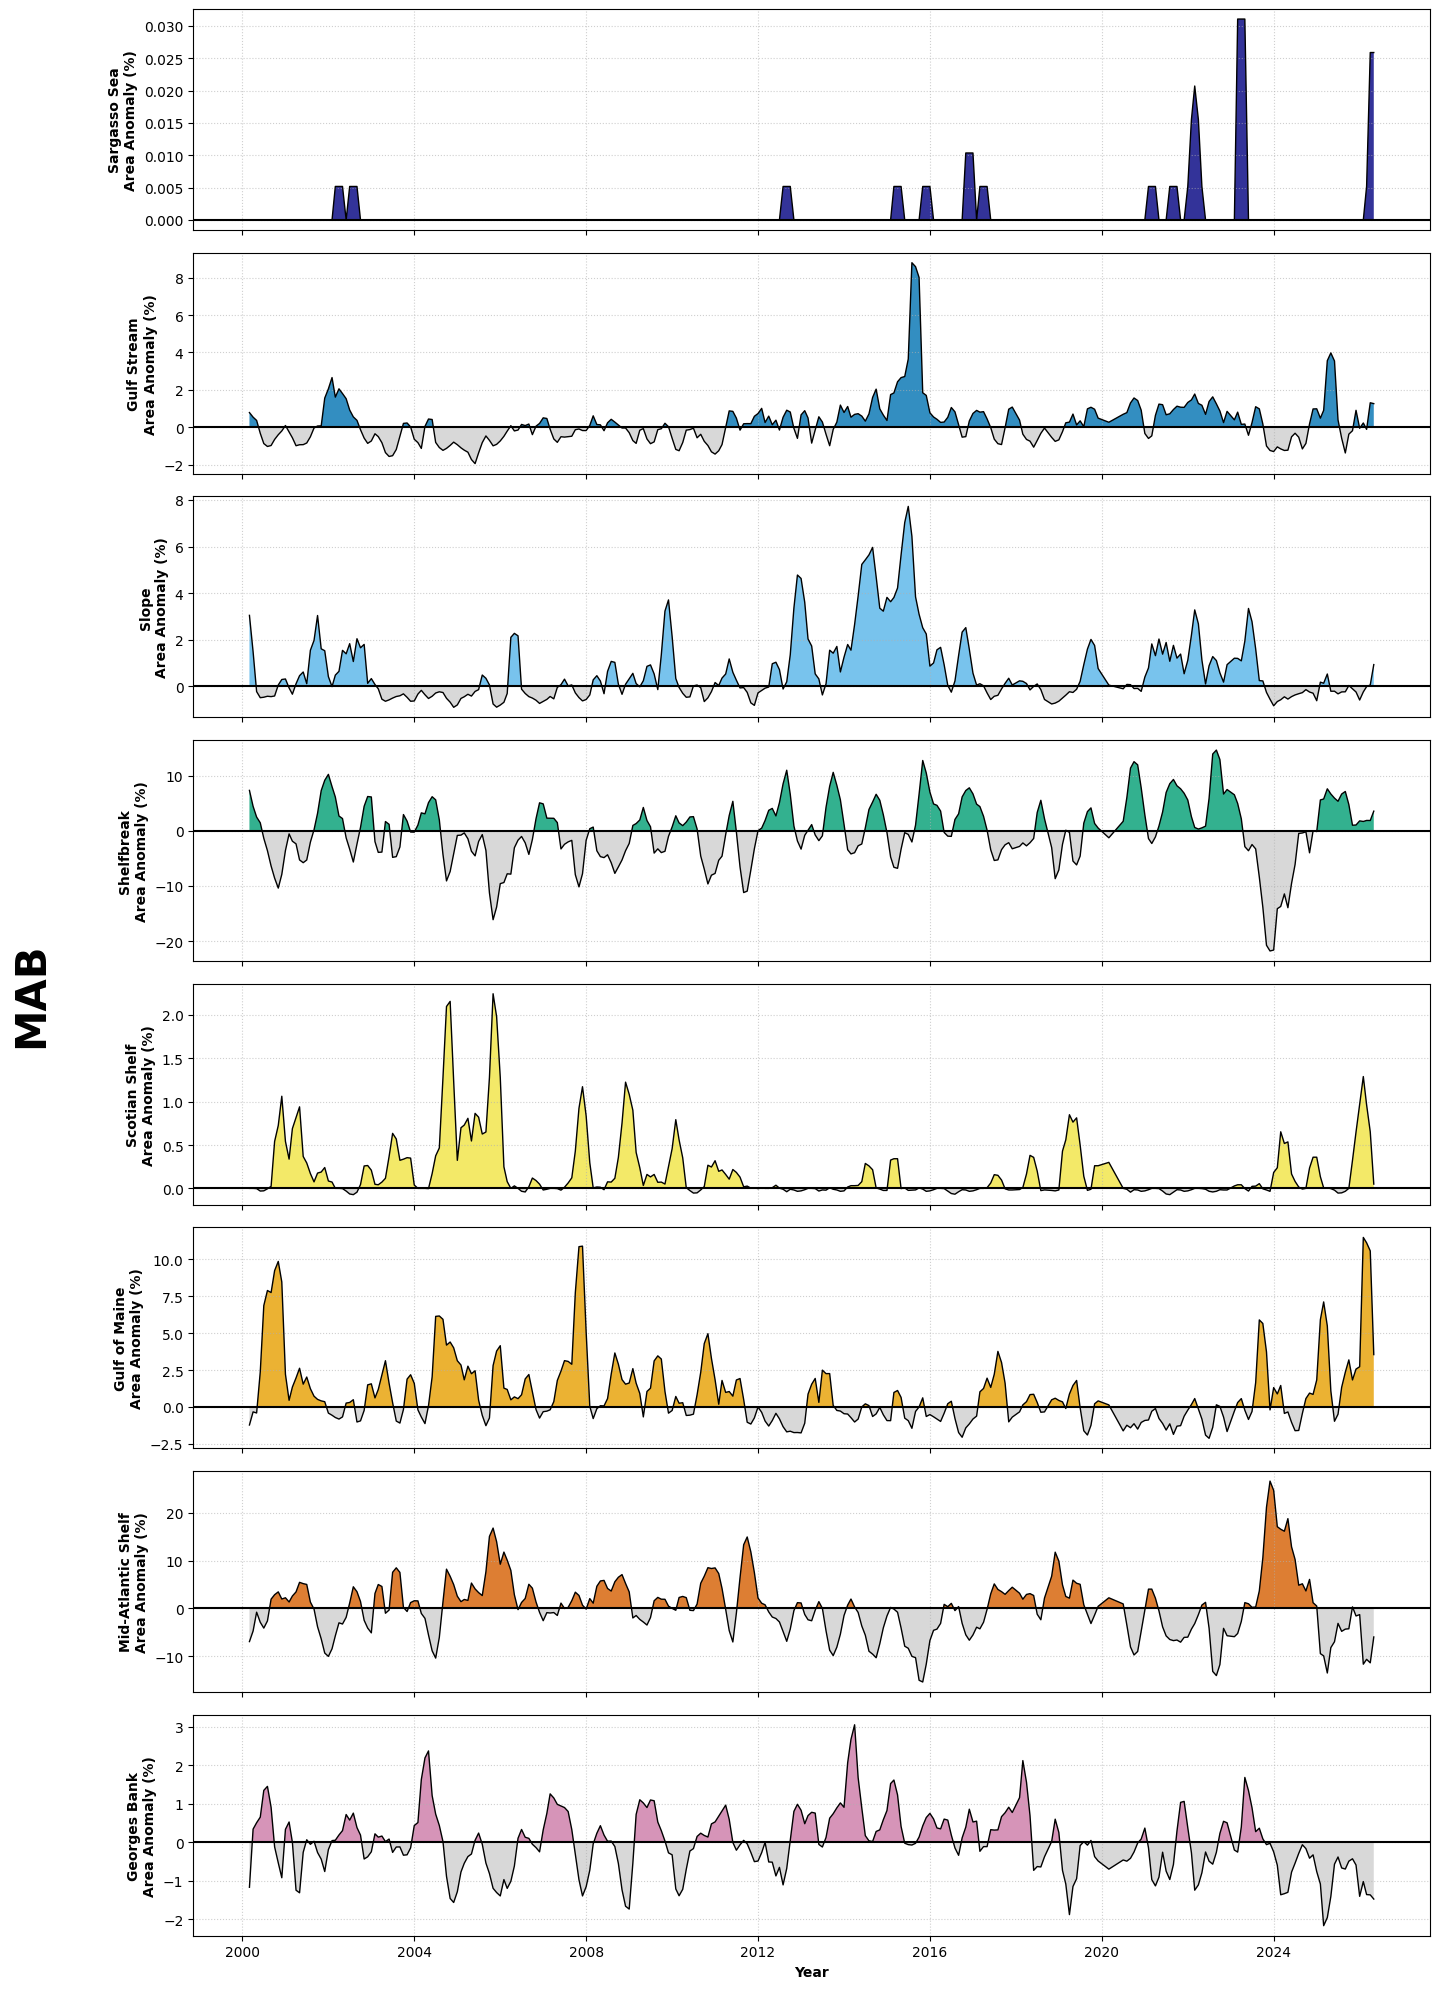

Getting SS for GB


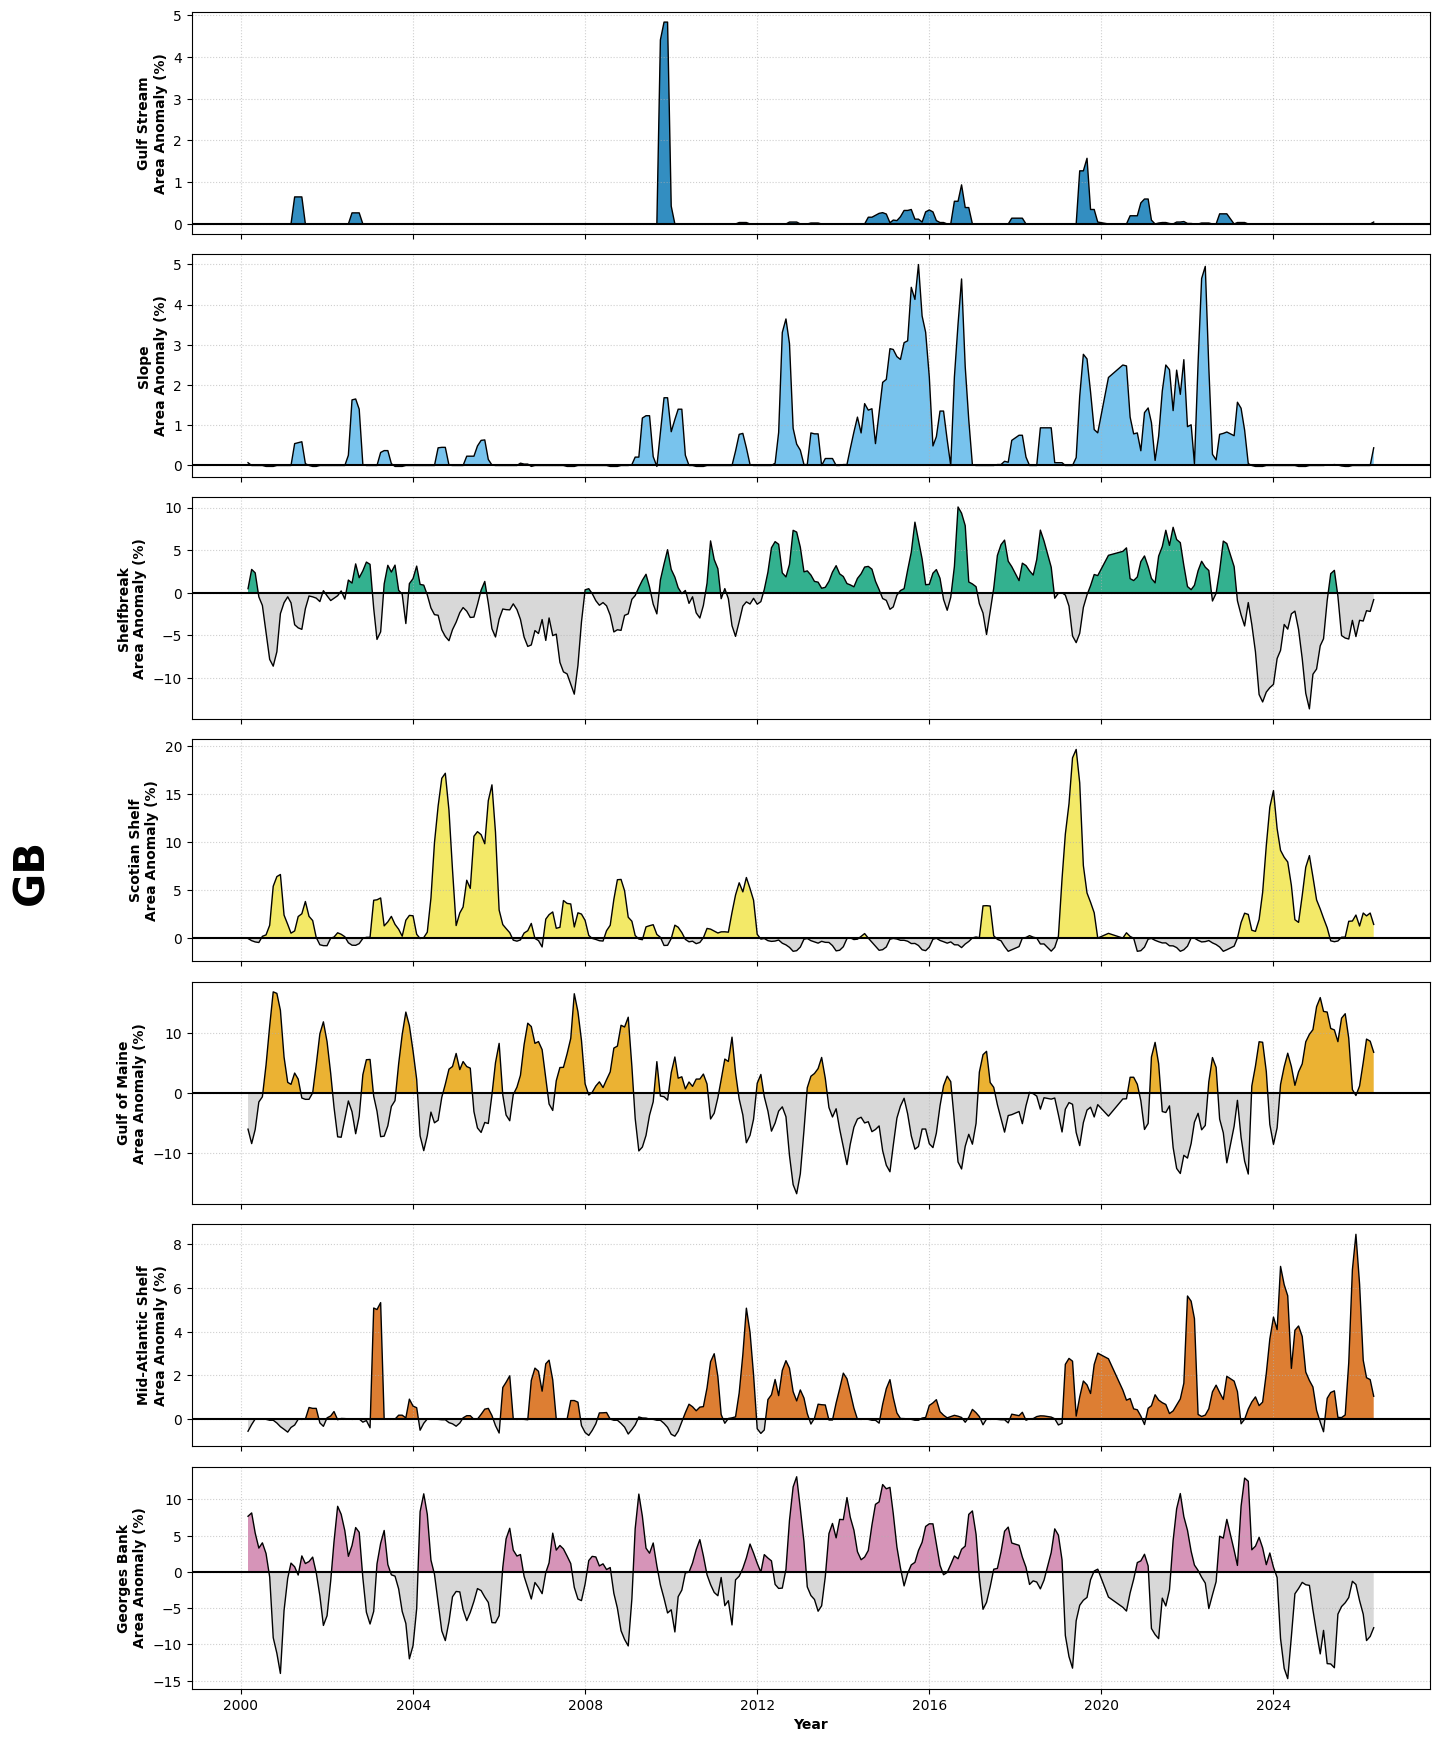

Getting GB+ for GOM


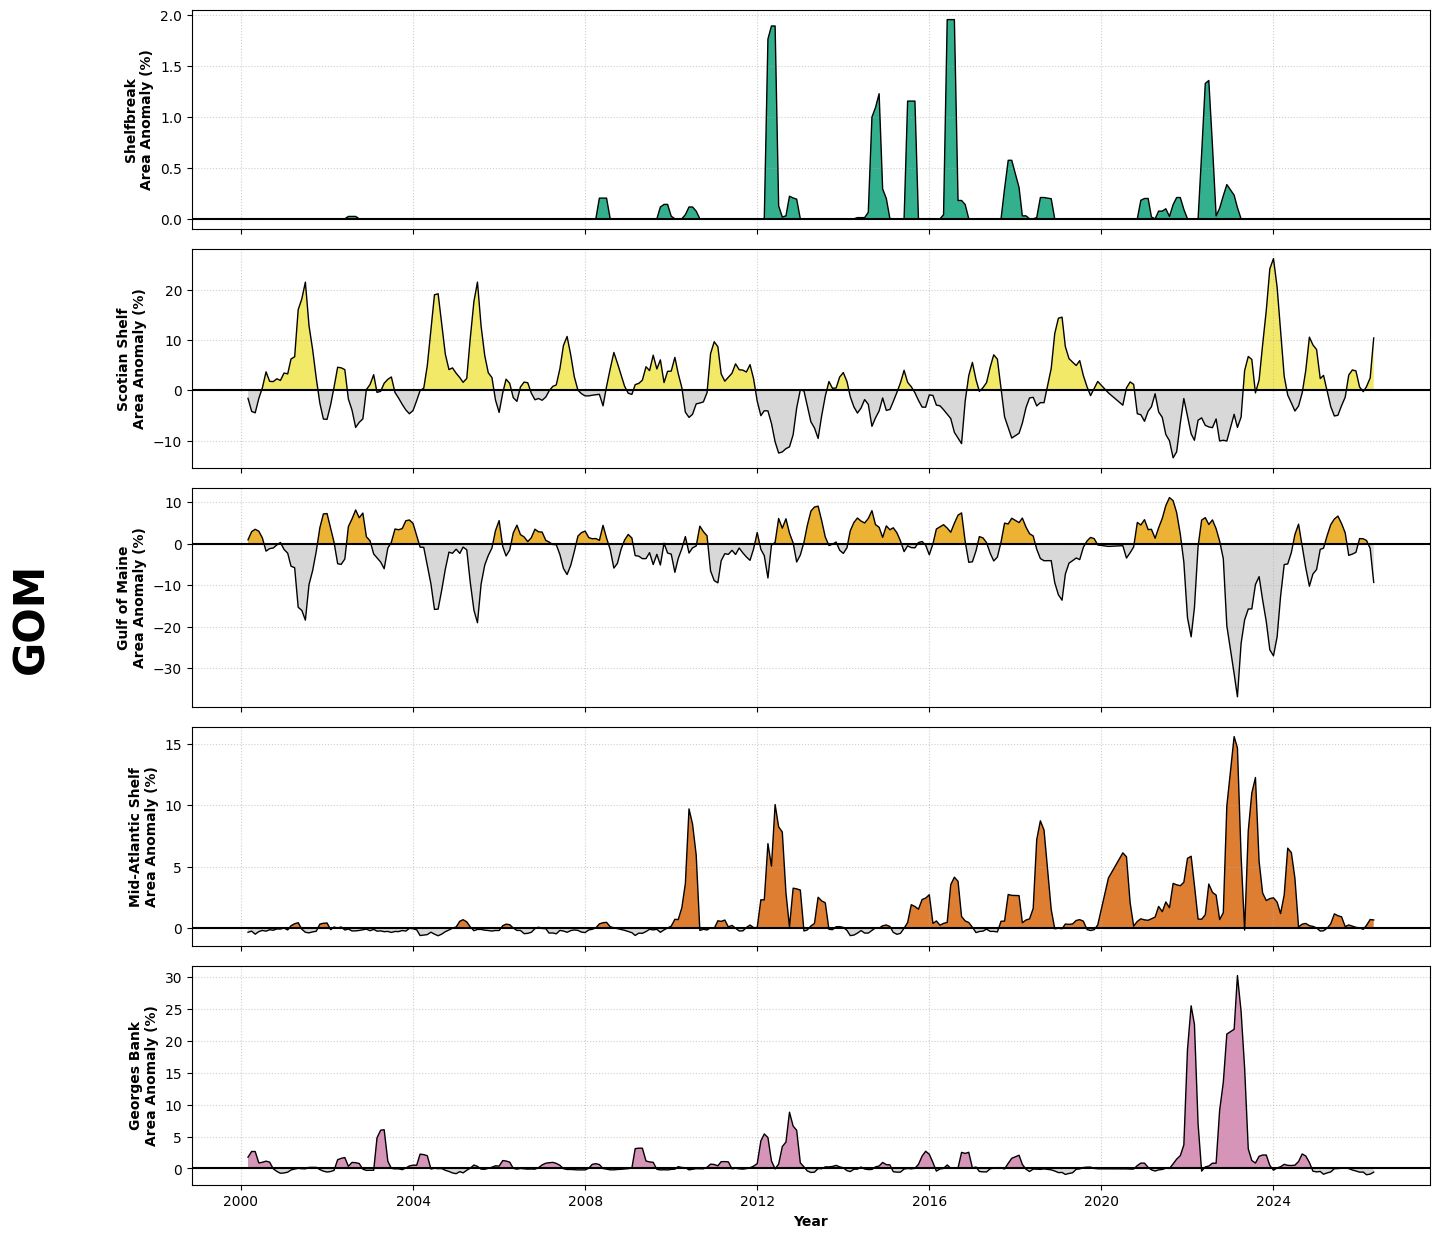

In [14]:
specific=[]
for xx in range(0,3):
    first_polygon = gdf.iloc[poly_list[xx]] # Using iloc[[0]] instead of iloc[0] returns a GeoDataFrame, keeping the CRS
    if ds.rio.crs is None:
        ds.rio.write_crs("EPSG:4326", inplace=True)
    first_polygon = first_polygon.to_crs(ds.rio.crs)
    clipped_ds = ds.rio.clip(
        first_polygon.geometry,
        first_polygon.crs,
        all_touched=True,
        drop=True # drop=True crops the spatial extent. False keeps original dimensions and pads with NaNs.
    )
    da = clipped_ds.water_mass
    unique_masses = np.arange(0,9)
    
    # 1. Calculate the % area covered by each water mass for every time step
    valid_water_pixels = da.notnull().sum(dim=['latitude', 'longitude'])
    
    mass_areas = []
    for mass in unique_masses:
        # Percentage of the region covered by this specific mass
        mass_area = (da == mass).sum(dim=['latitude', 'longitude']) / valid_water_pixels * 100
        mass_area.name = f'mass_{int(mass)}'
        mass_areas.append(mass_area)
    
    # Combine into a single Dataset
    ds_areas = xr.merge(mass_areas).load()
    
    # 2. Calculate the climatological normal area for each month
    climatology_areas = ds_areas.groupby('time.month').median(dim='time')
    #climatology_areas = ds_areas.groupby('time.month').mean(dim='time')
    
    # 3. Calculate the Anomaly (Actual Area % minus Normal Area %)
    # Apply a 3-month rolling mean to smooth out small/short term anomlaies
    area_anomalies = (ds_areas.groupby('time.month') - climatology_areas).rolling(time=3, center=True).mean()
    clean_unique_masses = [m for m in np.unique(da) if not np.isnan(m)]
    
    # 2. Dynamically size the figure based on the actual number of water masses
    fig, axes = plt.subplots(nrows=len(clean_unique_masses), figsize=(14, 2.5 * len(clean_unique_masses)), sharex=True)
    
    # Handle the edge case where there is only 1 water mass (axes wouldn't be an array)
    if len(clean_unique_masses) == 1:
        axes = [axes]
    
    for i, mass in enumerate(clean_unique_masses):
        ax = axes[i]
        ts = area_anomalies[f'mass_{int(mass)}']
        
        c = dis_hex[int(mass)]
        
        ax.plot(ts.time, ts, color='black', linewidth=1)
        
        # Fill above zero (Expansion)
        ax.fill_between(ts.time, 0, ts, where=(ts > 0), facecolor=c, alpha=0.8, interpolate=True)
        
        # Fill below zero (Retreat)
        ax.fill_between(ts.time, 0, ts, where=(ts < 0), facecolor='gray', alpha=0.3, interpolate=True)
        
        ax.axhline(0, color='black', linewidth=1.5)
        ax.set_ylabel(f'{wmass_labels[int(mass)]}\nArea Anomaly (%)', fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        if xx ==0 and mass ==2:
            print('Getting Slope for MAB')
            specific.append(ts)
        elif xx == 1 and mass == 4:
            print('Getting SS for GB')
            specific.append(ts)
        elif xx ==2 and mass == 7:
            print('Getting GB+ for GOM')
            specific.append(ts)
        
    
    axes[-1].set_xlabel('Year', fontweight='bold')
    #fig.suptitle(f'Water Mass Anomalies (3-Month Smoothed)\n{poly_name[xx]}', fontsize=16, fontweight='bold',y=0.99)
    fig.supylabel(poly_name[xx], fontweight='bold',fontsize=30, x=-0.025)
    plt.tight_layout()
    
    plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\{poly_name[xx]}_anomaly_timeseries.jpg')
    plt.show()

# Temporal plots

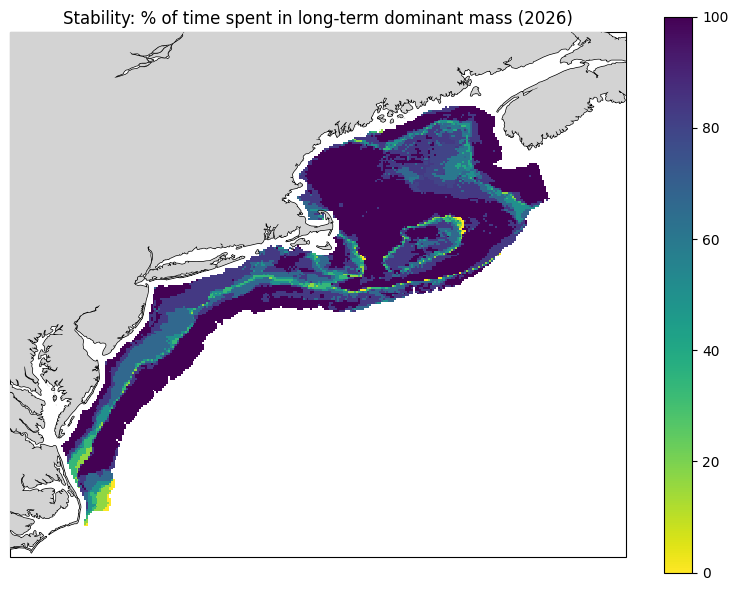

In [58]:
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pandas as pd
import xarray as xr
ds = ds.rio.write_crs("EPSG:4326")
gdf = gdf.to_crs(ds.rio.crs)
clipped_ds = ds.rio.clip(gdf.geometry, crs=gdf.crs, drop=True, invert=False)
# 1. Calculate the frequency of EVERY water mass per pixel (Full 26 years)
da = clipped_ds.water_mass
counts = []
for cat in categories:
    cat_count = (da == cat).sum(dim='time')
    counts.append(cat_count)

# Stack them into a new 3D xarray with 'category' as a dimension
counts_da = xr.concat(counts, dim=pd.Index(categories, name='category'))

# 2. Find the long-term dominant water mass per pixel (Full 26 years)
dominant_mass = counts_da.idxmax(dim='category')

# ---------------------------------------------------------
# NEW: Isolate and calculate variability for the most recent year
# ---------------------------------------------------------
# Extract the last 12 months of data (assuming monthly frequency)
da_recent = clipped_ds.sel(time=(ds.time.dt.year == 2026))#da.isel(time=slice(-12, None))

# Count valid time steps in just the last year (to safely handle land/NaNs)
recent_valid_steps = da_recent.notnull().sum(dim='time')

# Count how many months in the recent year MATCHED the long-term dominant mass
recent_matches = (da_recent == dominant_mass).sum(dim='time')

# Calculate the stability percentage for just this recent year
recent_stability_pct = (recent_matches / recent_valid_steps.where(recent_valid_steps > 0)) * 100

# Extract the actual year for the plot title dynamically
recent_year = pd.to_datetime(da_recent.time.values[-1]).year


fig = plt.figure(figsize=(8, 6)) 
map_projection = cartopy.crs.PlateCarree() 
ax = plt.axes(projection=map_projection) 

im=ax.pcolormesh(recent_stability_pct.longitude,recent_stability_pct.latitude,recent_stability_pct.water_mass,cmap='viridis_r', 
    # vmin set to 0 because over a single year, a pixel might completely diverge (0 matches)
    vmin=0, vmax=100, )
fig.colorbar(im,ax=ax)
ax.add_feature(cartopy.feature.COASTLINE, linewidth=1) 
ax.add_feature(cartopy.feature.LAND, zorder=100, facecolor='lightgrey') 
ax.set_extent([-77, -63.5, 34.5, 46])

plt.title(f"Stability: % of time spent in long-term dominant mass ({recent_year})")
plt.tight_layout()
plt.savefig(fr'C:\Users\haley.synan\Documents\PROJECTS\SOE_watermass\FIGURES\temporal_stability_2026.jpg')
plt.show()